# Python 与 PyTorch 入门讲义 · Week 1–4

四周的终点是**取出一批 FashionMNIST 图片和标签，并能解释每个维度代表什么**。Week 1–2 补齐 Python 语法，Week 3–4 对应官方的 Tensors、Datasets & DataLoaders、Transforms 三章。代码示例沿用官方教程的 API，并从小数据逐步过渡到真实图片。[PyTorch Learn the Basics](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)

| 周次 | 核心问题 | 课后能做什么 |
|---|---|---|
| Week 1 | Python 怎样存数据、遍历和筛选？ | 用循环求平均值，筛出高于平均值的记录 |
| Week 2 | 怎样把代码变成可以反复调用的函数和对象？ | 写函数，读懂 `self`、`len(dataset)` 和 `dataset[i]` |
| Week 3 | 张量怎样描述和计算多维数据？ | 预测切片、变形和矩阵乘法的输出形状 |
| Week 4 | 一张图怎样变成模型可读取的一批输入？ | 用 `Dataset` 读单条，用 `DataLoader` 取批次，核对图像与标签 |

在 Colab 上传这份 `.ipynb`，或者在本地 Jupyter/VS Code 中打开。点选代码单元后用 **Shift + Enter** 运行。建议按顺序执行；打开新运行时后需要重新执行依赖的单元。Week 1–2 只用 Python 标准库，Week 3 用 PyTorch，Week 4 还用到 TorchVision，画图单元另需 Matplotlib。全部示例可用 CPU。若本地缺少 PyTorch 或 TorchVision，按官方安装页为当前 Notebook 内核选择成对的安装命令。[PyTorch 本地安装](https://pytorch.org/get-started/locally/)

每周的第一个小时可分成 **15 分钟阅读、30 分钟运行并改代码、15 分钟练习和核对**。有第二小时就从空白单元重写当周核心例子，或做标注为选学的内容。第一次下载 FashionMNIST 需要联网；下载受阻时仍可完成第四周的离线示例。

## Week 1 · Python 基础

### 1.1 变量、列表和索引

`scores = [72, 86, 68, 94]` 把列表绑定到名字 `scores`。列表里的整数属于 `int`，除法 `/` 的结果通常是 `float`，文字是 `str`，比较表达式产生 `bool`。可以用 `type(value)` 观察类型。

- 索引从 **0** 开始。`scores[0]` 是第一项，`scores[-1]` 是最后一项。
- 切片 `scores[1:3]` 取索引 1 和 2。右端点 3 不包含在结果中。
- `len(scores)` 返回元素个数。长度为 4 时，可用的非负索引为 0 到 3。
- `print` 把结果显示出来。形如 `f"平均分 {mean_score:.1f}"` 的字符串会把变量值格式化到小数点后一位。

In [1]:
scores = [72, 86, 68, 94]

print("第一项和最后一项", scores[0], scores[-1])
print("中间两项", scores[1:3])
print("长度", len(scores))
print("元素类型", type(scores[0]))
print("第一项是否大于 80", scores[0] > 80)

第一项和最后一项 72 94
中间两项 [86, 68]
长度 4
元素类型 <class 'int'>
第一项是否大于 80 False


### 1.2 用循环计算平均值，再筛选

`for score in scores:` 每次取出一个元素，赋给 `score`。下一行的四个空格表示它属于循环体。先累加再除以长度，运行完循环后的 `total` 应是 320。第二次遍历时，`if score > mean_score:` 只给满足条件的分数执行 `append`。`>` 是严格大于；若题目要求“至少等于”，改用 `>=`。

In [ ]:
scores = [72, 86, 68, 94]
total = 0
for score in scores:
    total += score

mean_score = total / len(scores)
above_mean = []
for score in scores:
    if score > mean_score:
        above_mean.append(score)

print(f"平均分 {mean_score:.1f}")
print("严格高于平均分", above_mean)

### 1.3 元组、字典与一起读取两个值

`("Ada", 72)` 是一个元组，可以表示一条由姓名和分数组成的记录。`for name, score in records` 每轮把两个值拆开，这与 Week 4 的 `for images, labels in loader` 是同一种写法。字典通过键定位：`label_names[1]` 表示整数键 1 对应的文字。

In [2]:
records = [("Ada", 72), ("Bo", 86)]
for name, score in records:
    print(f"{name}: {score}")

label_names = {0: "上衣", 1: "裤子"}
print(label_names[1])

Ada: 72
Bo: 86
裤子


### Week 1 练习

1. 把分数换成 `[60, 75, 90, 75]`，先手算平均分，再用循环筛出严格高于平均分的值。
2. 把比较条件改成 `>=`，预测结果比上一题多出哪些值。保留重复记录。
3. 选学。用 `enumerate` 打印严格高于平均分的值及其从 0 开始的索引。

**核对。** 平均分为 75.0。第一题得到 `[90]`，第二题得到 `[75, 90, 75]`，第三题只有索引 2。

**常见报错。** `IndexError` 通常表示索引超出范围；报 `NameError` 时先核对变量拼写和定义单元是否运行过；缩进报错时检查循环体和条件体是否各自缩进。

## Week 2 · 函数、导入和类

### 2.1 函数的输入与输出

`def` 定义函数，调用时才执行里面的代码。`return` 把结果交给调用者，所以结果可以保存到变量，也可以参与下一次计算。`raise ValueError(...)` 在输入违背函数约定时直接报告原因。这里约定输入是一个非空的数字列表。

In [3]:
def average(values):
    if len(values) == 0:
        raise ValueError("average 需要至少一个数字")

    total = 0
    for value in values:
        total += value
    return total / len(values)


def above_threshold(values, threshold):
    selected = []
    for value in values:
        if value > threshold:
            selected.append(value)
    return selected


scores = [72, 86, 68, 94]
threshold = average(scores)
print(threshold, above_threshold(scores, threshold))
print(average([1, 2, 3]))

80.0 [86, 94]
2.0


调用 `average(scores)` 时，形参 `values` 接收列表，`total` 则是在函数内部使用的局部变量。若函数只写 `print(total / len(values))`，调用时会显示结果，但调用表达式的值会是 `None`。标准库里已有 `statistics.mean`；手写一次有助于理解处理步骤。

### 2.2 导入和调用

`import math` 导入模块后通过 `math.sqrt` 调用函数。`from statistics import mean` 把函数名直接导入，之后可以写 `mean(...)`。Week 3 的 `import torch` 用第一种写法；Week 4 的 `from torch.utils.data import DataLoader` 用第二种。

In [ ]:
import math
from statistics import mean

print(math.sqrt(81))
print(mean([60, 75, 90, 75]))

### 2.3 用一个小类预习 Dataset

创建 `ScoreRecords(...)` 会调用 `__init__`，用 `self.rows` 保存这个对象自己的数据。`len(records)` 会调用 `__len__`，`records[1]` 会调用 `__getitem__`。带双下划线的方法名是 Python 约定的接口。Week 4 会用这组接口封装不同类型的数据。

In [4]:
class ScoreRecords:
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        return self.rows[index]


score_records = ScoreRecords([("Ada", 72), ("Bo", 86), ("Cai", 68)])
name, score = score_records[1]
print(len(score_records))
print(name, score)

3
Bo 86


### Week 2 练习

1. 写一个 `select_at_least(values, threshold)` 函数，返回大于或等于阈值的元素。用 `[60, 75, 90, 75]` 和阈值 75 验证。
2. 用 `ScoreRecords` 存两条自选记录。打印长度，然后拆包第二条记录。
3. 选学。用 `try/except ValueError` 调用 `average([])`，打印异常消息。预期能看到函数里写的消息。

**核对。** 第 1 题应得到 `[75, 90, 75]`；可以沿用 `above_threshold` 的循环，把条件改成 `value >= threshold`。第 2 题中 `len` 应返回 2，索引 1 应返回第二条记录。

**常见报错。** 出现 `TypeError: ... NoneType` 时，检查函数是否在所有正常路径上都返回预期结果。看到 `ModuleNotFoundError`，先核对模块名和当前 Notebook 使用的环境。

## Week 3 · 张量 Tensors

### 3.1 创建张量并检查属性

张量用规则的多维结构存放同一类型的数据。`shape` 给出每个维度的长度；`ndim` 是维度个数；`dtype` 是元素类型；`device` 表示张量所在的设备。后续排查模型输入时，通常先打印 `shape` 和 `dtype`。

| 示例 | 形状 | 直观含义 |
|---|---|---|
| `torch.tensor(7)` | `()` | 标量 |
| `torch.tensor([3, 7])` | `(2,)` | 两元素向量 |
| `torch.tensor([[1, 2, 3], [4, 5, 6]])` | `(2, 3)` | 2 行 3 列 |
| 一张 FashionMNIST 图片 | `(1, 28, 28)` | 1 个通道，高 28、宽 28 |
| 一批 32 张图片 | `(32, 1, 28, 28)` | 批次、通道、高、宽 |

同样是 `(2,)` 和 `(1, 2)`，元素个数相同，维度个数不同。后者可以理解成一行两列，前者只有一条轴。[官方 Tensors 教程](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)

In [2]:
import torch

matrix = torch.tensor([[1, 2, 3], [4, 5, 6]], dtype=torch.float32)
print("shape", tuple(matrix.shape))
print("ndim", matrix.ndim)
print("dtype", matrix.dtype)
print("device", matrix.device)

print("全零", torch.zeros((2, 3)))
print("同形状、同类型、同设备的全一张量", torch.ones_like(matrix))
print("随机数示例", torch.rand((2, 3)))

shape (2, 3)
ndim 2
dtype torch.float32
device cpu
全零 tensor([[0., 0., 0.],
        [0., 0., 0.]])
同形状、同类型、同设备的全一张量 tensor([[1., 1., 1.],
        [1., 1., 1.]])
随机数示例 tensor([[0.4247, 0.9391, 0.4356],
        [0.0287, 0.1997, 0.3836]])


### 3.2 索引、切片、变形

用逗号分隔行和列索引。整数索引通常去掉对应的轴，长度为 1 的切片可以保留该轴。所以 `matrix[:, 1]` 形状为 `(2,)`，而 `matrix[:, 1:2]` 形状为 `(2, 1)`。

`reshape` 按原来的元素顺序重新分组，元素总数必须一致。下面 6 个元素可以变成 `(3, 2)`，也可写成 `reshape(3, -1)`，由 PyTorch 推断剩下的维度。转置交换行列，与按元素顺序重新分组的 `reshape` 会得到不同的值。

In [9]:
print("第一行", matrix[0])
print("第二列", matrix[:, 1],tuple(matrix[:, 1].shape))
print("保留列维度", matrix[:, 1:2], tuple(matrix[:, 1:2].shape))
print("变形成 3×2", matrix.reshape(3, -1))
print("转置成 3×2", matrix.T)

第一行 tensor([1., 2., 3.])
第二列 tensor([2., 5.]) (2,)
保留列维度 tensor([[2.],
        [5.]]) (2, 1)
变形成 3×2 tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])
转置成 3×2 tensor([[1., 4.],
        [2., 5.],
        [3., 6.]])


### 3.3 逐元素、矩阵乘法和按维度求和

- `matrix * matrix` 对应位置相乘，结果形状仍是 `(2, 3)`。
- `matrix @ matrix.T` 做矩阵乘法。`(2, 3) @ (3, 2)` 得到 `(2, 2)`，例如左上角是 `1² + 2² + 3² = 14`。
- `sum(dim=0)` 沿第 0 维把各行相加，得到每列的和；`sum(dim=1)` 沿第 1 维把各列相加，得到每行的和。观察哪个轴在结果中消失。
- `.sum()` 得到标量张量；`.item()` 把只有一个元素的张量取成 Python 数值。

In [3]:
print("逐元素乘法", matrix * matrix)
print("矩阵乘法", matrix @ matrix.T)
print("各列之和", matrix.sum(dim=0))
print("各行之和", matrix.sum(dim=1))

total = matrix.sum()
print("标量张量", total, "Python 数值", total.item())

逐元素乘法 tensor([[ 1.,  4.,  9.],
        [16., 25., 36.]])
矩阵乘法 tensor([[14., 32.],
        [32., 77.]])
各列之和 tensor([5., 7., 9.])
各行之和 tensor([ 6., 15.])
标量张量 tensor(21.) Python 数值 21.0


### 3.4 广播、拼接与 NumPy（选学）

广播从最后一个维度开始比较各轴长度。长度相等或其中一个是 1 时可对齐，缺少的前置轴按长度为 1 处理。`(2, 3) + (3,)` 会把三个增量分别加到每一行。`cat` 沿已有轴拼接；`stack` 增加一条新轴，Week 4 的批次维就可以这样理解。

官方教程也展示了 CPU 张量与 NumPy 数组的内存共享。下面的 `torch.from_numpy(array)` 共享内存，改数组会影响张量；需要独立数据时可以对张量做 `clone()`。以 `_` 结尾的许多张量方法（如 `add_`）会直接修改原张量。[官方 Tensors 教程 · Bridge with NumPy](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html#bridge-with-numpy)

In [8]:
import numpy as np

offsets = torch.tensor([10.0, 20.0, 30.0])
print("广播结果", matrix + offsets)
print("沿行拼接", tuple(torch.cat([matrix, matrix], dim=0).shape))
print("新增一条轴", tuple(torch.stack([matrix, matrix], dim=2).shape))

array = np.array([3, 4, 5], dtype=np.float32)
shared = torch.from_numpy(array)
independent = shared.clone()
array[0] = 99
print("共享", shared, "独立副本", independent)

广播结果 tensor([[11., 22., 33.],
        [14., 25., 36.]])
沿行拼接 (4, 3)
新增一条轴 (2, 3, 2)
共享 tensor([99.,  4.,  5.]) 独立副本 tensor([3., 4., 5.])


### Week 3 练习

新建 `x = torch.tensor([[2., 4., 6.], [1., 3., 5.]])`，每题先写下你预测的形状和值，再运行核对。

1. 取最后一列，分别得到 `(2,)` 和 `(2, 1)`。
2. 变成 `(3, 2)` 并对照 `x.T`。它们第一行各是什么？
3. 计算每行平均值，然后算 `x @ x.T`。

**核对。** 第 1 题可用 `x[:, -1]` 和 `x[:, -1:]`，两者都取到 6 和 5。第 2 题 `x.reshape(3, 2)[0]` 为 `[2., 4.]`，`x.T[0]` 为 `[2., 1.]`。第 3 题 `x.mean(dim=1)` 为 `[4., 3.]`，矩阵乘法结果为 `[[56., 44.], [44., 35.]]`。

**常见报错。** `reshape` 失败先核对元素总数，矩阵乘法失败先核对内侧维度，`torch.mean` 遇到整数张量可先转成浮点。混合 CPU 与 GPU 张量运算前，需要先把参与运算的张量移到同一设备。

## Week 4 · Dataset、DataLoader 与 Transforms

### 4.1 先离线理解样本与批次

`Dataset` 规定如何按索引找出一条样本；每条样本在这里都是 `(image, label)`。`DataLoader` 负责选样本、打包并逐批交给循环。下方的五张玩具图片是几个常数矩阵，只用于观察形状。

`__len__` 返回样本数；`__getitem__` 返回指定索引处的一条数据。真实项目在这里也可以读取图像文件、查找标签并执行转换。打印批次时，用 `tuple(images.shape)` 看尺寸，之后用 `images[0]` 取第一张。遍历一次加载器就是遍历一轮数据；如果样本总数无法整除批大小，默认保留最后一个较小批次。

In [9]:
import torch
from torch.utils.data import DataLoader, Dataset


class ToyImageDataset(Dataset):
    def __init__(self):
        self.labels = [0, 1, 0, 1, 0]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = torch.full((1, 2, 2), index / 4)
        label = self.labels[index]
        return image, label


toy_data = ToyImageDataset()
toy_image, toy_label = toy_data[1]
print("单条样本", tuple(toy_image.shape), toy_label)

toy_loader = DataLoader(toy_data, batch_size=2, shuffle=False)
for batch_number, (images, labels) in enumerate(toy_loader, start=1):
    print(batch_number, tuple(images.shape), labels.tolist())

单条样本 (1, 2, 2) 1
1 (2, 1, 2, 2) [0, 1]
2 (2, 1, 2, 2) [0, 1]
3 (1, 1, 2, 2) [0]


先预测再运行。这个循环的批次大小应依次是 2、2、1；图片形状分别为 `(2, 1, 2, 2)`、`(2, 1, 2, 2)`、`(1, 1, 2, 2)`，最后一批的标签张量形状仍是 `(1,)`。`next(iter(toy_loader))` 则只取第一批，适合检查输入。

### 4.2 FashionMNIST 与图片转换

FashionMNIST 有 **60,000 张训练图片和 10,000 张测试图片**。每张是 28×28 的灰度图片，标签是十个类别之一。使用 `root` 指定缓存目录，`train` 选择官方训练或测试划分，`download=True` 会在需要时下载数据。

`transform` 用于图片，`target_transform` 用于标签。图片转换按官方教程使用 TorchVision v2：

1. `v2.ToImage()` 把数据集交出的 PIL 图片转换成图片张量，保留原像素类型和取值。
2. `v2.ToDtype(torch.float32, scale=True)` 把这里的 8 位像素转换成浮点数，并从 0–255 缩放到 0–1。
3. `v2.Compose` 把上面两步按顺序串起来。实际观察到的最小值和最大值可能只占 0–1 的一部分。

[官方 Datasets & DataLoaders 教程](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html) · [官方 Transforms 教程](https://docs.pytorch.org/tutorials/beginner/basics/transforms_tutorial.html)

In [10]:
from torchvision import datasets
from torchvision.transforms import v2

image_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

# 首次运行下一节前，可先用离线张量验证缩放。
pixel_demo = torch.tensor([[[0, 128, 255]]], dtype=torch.uint8)
float_pixels = image_transform(pixel_demo)
print(float_pixels, float_pixels.dtype)

Image([[[0.0000, 0.5020, 1.0000]]], ) torch.float32


预期得到约 `[0.0000, 0.5020, 1.0000]`。这一步只需要已经装好 PyTorch 和 TorchVision。

### 4.3 下载、检查单条样本和显示图片

这一单元首次运行时尝试下载数据。缓存位于当前工作目录下的 `data/`。使用已经完整下载的同一缓存时，可以将 `download` 改为 `False`。如果下载受阻，可跳到 4.5 的离线标签转换，并用 4.1 的数据完成批次练习。

In [11]:
train_data = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=image_transform
)
test_data = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=image_transform
)

image, label = train_data[0]
print("训练 / 测试样本数", len(train_data), len(test_data))
print("图片形状 / 类型", tuple(image.shape), image.dtype)
print("像素范围", image.min().item(), image.max().item())
print("标签编号 / 类别", label, train_data.classes[label])

100%|██████████| 26.4M/26.4M [00:05<00:00, 4.80MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 149kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.60MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.3MB/s]

训练 / 测试样本数 60000 10000
图片形状 / 类型 (1, 28, 28) torch.float32
像素范围 0.0 1.0
标签编号 / 类别 9 Ankle boot


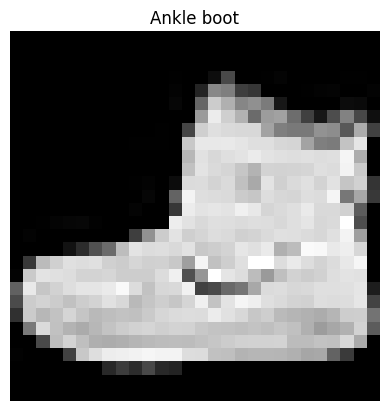

In [12]:
# 可选：显示 4.3 读到的灰度图。
import matplotlib.pyplot as plt

plt.imshow(image[0], cmap="gray", vmin=0, vmax=1)
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

单张图的形状应为 `(1, 28, 28)`。这里用 `image[0]` 取出唯一通道，把 `(28, 28)` 的二维矩阵交给画图函数。`label` 是单条样本的整数标签，类别名称可以通过数据集的 `classes` 查找。

### 4.4 取一个真实批次

训练加载器用 `shuffle=True`，遍历时以打乱的顺序取样本；测试加载器保留顺序，方便复查错例。这里用 `num_workers=0` 在当前进程读取数据，让示例也能直接在 Windows Notebook 运行。初次检查批次时，注意对比图片的四个维度和标签的一条维度。

In [13]:
train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("图片批次", tuple(images.shape), images.dtype)
print("标签批次", tuple(labels.shape), labels.dtype)
print("第一张图片", tuple(images[0].shape))
print("第一个标签和类别", labels[0].item(), train_data.classes[labels[0].item()])

test_images, test_labels = next(iter(test_loader))
print("测试批次", tuple(test_images.shape), tuple(test_labels.shape))

图片批次 (32, 1, 28, 28) torch.float32
标签批次 (32,) torch.int64
第一张图片 (1, 28, 28)
第一个标签和类别 3 Dress
测试批次 (32, 1, 28, 28) (32,)


训练首批图片、标签形状应为 `(32, 1, 28, 28)` 和 `(32,)`。原来每个标签是 Python 整数，默认打包后得到 `torch.int64` 张量。`images[i]` 和 `labels[i]` 对应同一条样本，即使打乱顺序也会保持配对。

### 4.5 选学。用 target_transform 理解 one-hot

官方转换章节用 `target_transform` 展示 one-hot：类别编号 3 变成长度为 10 的向量，位置 3 上是 1，其余位置为 0。下方先直接调用转换观察结果，也可把 `target_transform=encode_target` 传给 `datasets.FashionMNIST(...)`，再检查一个批次。主线例子保留整数类别索引，后续可以直接用于常见的 `CrossEntropyLoss` 类别索引用法。[官方 Transforms 教程 · Lambda Transforms](https://docs.pytorch.org/tutorials/beginner/basics/transforms_tutorial.html#lambda-transforms)

In [14]:
from torch.nn import functional as F


def encode_target(label):
    return F.one_hot(torch.tensor(label), num_classes=10).to(torch.float32)


encoded = encode_target(3)
print(encoded)
print("形状", tuple(encoded.shape))
print("还原类别", encoded.argmax().item())

tensor([0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])
形状 (10,)
还原类别 3


### Week 4 练习

1. 把 FashionMNIST 的批大小改为 16，再取第一批。先预测张量形状和标签类型，随后运行核对。
2. 用 `shuffle=False` 创建一个训练加载器，比较第一批的首张图片、首个标签与 `train_data[0]`。图片可以用 `torch.equal` 检查。
3. 选学。把离线玩具数据的批大小设为 3，然后尝试 `drop_last=True`。比较最后一批是否还会返回。

**核对。** 第 1 题应得到 `(16, 1, 28, 28)` 的浮点图片和 `(16,)` 的整数标签。第 2 题首张图片与标签都应相同。第 3 题默认批大小依次为 3 和 2，开启 `drop_last=True` 后只剩第一批。

**排错顺序。** `import torchvision` 若报算子找不到，检查 Notebook 内核中 `torch`、`torchvision` 是否是同一安装来源的兼容组合；数据下载失败时检查网络和缓存目录；绘图遇到形状错误时，打印传给 `imshow` 的形状，并对这份灰度图显式取 `image[0]`。

### 四周验收

找一个空白单元，重新写出从训练数据取首批的代码，并用一句话分别解释：

- `train_data[0]` 返回的两个值是什么？图像的三个维度分别表示什么？
- 为什么 `DataLoader` 产生的图片会多出一条轴？
- 把批大小改成 16，哪些维度会变？如果最后样本数不够，默认会怎样？
- 图片从 8 位像素转换成浮点数经过了哪两步？类别索引表示什么？

能用打印结果支撑这些回答，就可以接 Week 5 的模型构建。到那时可以把形状为 `(B, 1, 28, 28)` 的图片批次送进模型，并追踪每张图片如何得到 10 个类别分数。[官方 Build the Neural Network](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html)